In [123]:
# libraries : data handling, numeric ops, plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [124]:
# load the dataset
df = pd.read_csv('/content/Food delivery.csv')

In [125]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [126]:
# quick look at the first rows
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [127]:
# rows X columns
df.shape

(45593, 20)

In [128]:
# datatypes + nullcounts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

Now we have to clean the data by observing it and understanding the flaws !!!
starting with the weather conditions...


In [129]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
conditions Fog,7654
conditions Stormy,7586
conditions Cloudy,7536
conditions Sandstorms,7495
conditions Windy,7422
conditions Sunny,7284
conditions NaN,616


In [130]:
temp="conditions Fog"

In [131]:
temp.split(" ")[1] if pd.notnull(temp) else temp

'Fog'

In [132]:
# weather conditions arrives as "conditions sunny" - keep only the actual word
df['Weatherconditions']=df['Weatherconditions'].apply(lambda temp:temp.split(" ")[1] if pd.notnull(temp) else temp )

In [133]:
df['Weatherconditions']

,Weatherconditions
0,Sunny
1,Stormy
2,Sandstorms
3,Sunny
4,Cloudy
...,...
45588,Windy
45589,Windy
45590,Cloudy
45591,Cloudy


In [134]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='object')

In [135]:
# all text (object) columns
df.select_dtypes(include='object')

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,19-03-2022,11:30:00,11:45:00,Sunny,High,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,26-03-2022,13:30:00,13:45:00,Cloudy,High,Snack,scooter,1,No,Metropolitian,(min) 30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45588,0x7c09,JAPRES04DEL01,30,4.8,24-03-2022,11:35:00,11:45:00,Windy,High,Meal,motorcycle,0,No,Metropolitian,(min) 32
45589,0xd641,AGRRES16DEL01,21,4.6,16-02-2022,19:55:00,20:10:00,Windy,Jam,Buffet,motorcycle,1,No,Metropolitian,(min) 36
45590,0x4f8d,CHENRES08DEL03,30,4.9,11-03-2022,23:50:00,00:05:00,Cloudy,Low,Drinks,scooter,0,No,Metropolitian,(min) 16
45591,0x5eee,COIMBRES11DEL01,20,4.7,07-03-2022,13:35:00,13:40:00,Cloudy,High,Snack,motorcycle,1,No,Metropolitian,(min) 26


In [136]:
#For every text column: remove leading/trailing spaces, and turn the literal
#string 'NaN' (not a real null) into an actual np.nan so pandas treats it as missing
for col in df.select_dtypes(include='object').columns :
  df[col]=df[col].str.strip()
  df[col]=df[col].replace('NaN',np.nan)

In [137]:
df[df['Delivery_person_Age']=='NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [139]:
#Target column still stored as text, e.g. "(min) 24"
type(df['Time_taken(min)'][0])

str

In [140]:
temp='(min) 24'

In [141]:
int(temp.split(" ")[1]) if pd.notnull(temp) else temp

24

In [142]:
# Target cleanup: "(min) 24" -> 24 (int). Keep real NaNs as NaN instead of crashing on them
df['Time_taken(min)']=df['Time_taken(min)'].apply(lambda temp:int(temp.split(" ")[1]) if pd.notnull(temp) else temp )

In [143]:
df['Time_taken(min)']
type(df['Time_taken(min)'][0])

numpy.int64

In [144]:
# Force genuinely numeric columns to numeric dtype; errors='coerce' turns any
# leftover bad values into NaN instead of raising, so we can impute them next
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col]=pd.to_numeric(df[col],errors='coerce')

In [145]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [146]:
# Ratings shouldn't exceed 5 - clip any bad values (e.g. 6.0) back to the valid max
df[df['Delivery_person_Ratings']>5]['Delivery_person_Ratings']

,Delivery_person_Ratings
3586,6.0
4714,6.0
5169,6.0
5362,6.0
5651,6.0
6394,6.0
7031,6.0
7681,6.0
9499,6.0
9535,6.0


In [147]:
df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].clip(upper=5)

In [148]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.632567,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.331560,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [149]:
#Numeric columns: fill missing values with the median (robust to outliers/skew)
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col]=df[col].fillna(df[col].median())

In [150]:
# Categorical columns: fill missing values with the mode (most frequent category)
for col in ['Weatherconditions','Road_traffic_density','Festival','City'] :
  df[col].fillna(df[col].mode()[0],inplace=True)


/tmp/ipykernel_540/3779213148.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0],inplace=True)


In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

EDA

For every feature we ask : what does this looks like, and does it releate to delivery time ?

In [152]:
df['Time_taken(min)'].describe()

,Time_taken(min)
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


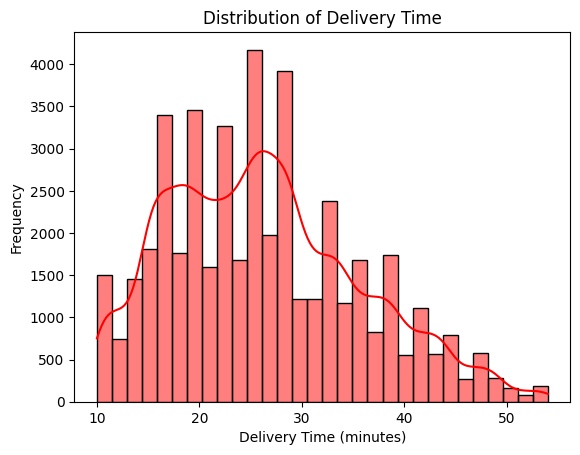

In [153]:
sns.histplot(df['Time_taken(min)'],bins=30, kde=True, color='red')
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Frequency")
plt.show()

In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [155]:
df['Road_traffic_density'].value_counts()

,count
Road_traffic_density,
Low,16078
Jam,14143
Medium,10947
High,4425


In [156]:
df.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.240000,27.0,8.396012
Jam,14143,31.176624,31.0,9.940904
Low,16078,21.464175,21.0,6.988438
Medium,10947,26.699644,27.0,8.560179


In [157]:
df.groupby('Weatherconditions')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Weatherconditions,,,,
Cloudy,7536,28.917330,28.0,10.084352
Fog,8270,28.739541,28.0,10.100816
Sandstorms,7495,25.875517,26.0,8.618434
Stormy,7586,25.870815,26.0,8.473273
Sunny,7284,21.856947,20.0,8.327210
Windy,7422,26.118836,26.0,8.615702


In [158]:
df['Festival'].value_counts()

,count
Festival,
No,44697
Yes,896


In [159]:
df.groupby('Festival')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Festival,,,,
No,44697,25.909256,25.0,9.052291
Yes,896,45.517857,45.0,4.001915


In [160]:
df.groupby('City')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
City,,,,
Metropolitian,35293,27.136486,26.0,9.205358
Semi-Urban,164,49.731707,49.0,2.693089
Urban,10136,22.984017,22.0,8.866011


In [161]:
df['Delivery_person_Age'].describe()

,Delivery_person_Age
count,45593.000000
mean,29.584739
std,5.696333
min,15.000000
25%,25.000000
50%,30.000000
75%,34.000000
max,50.000000


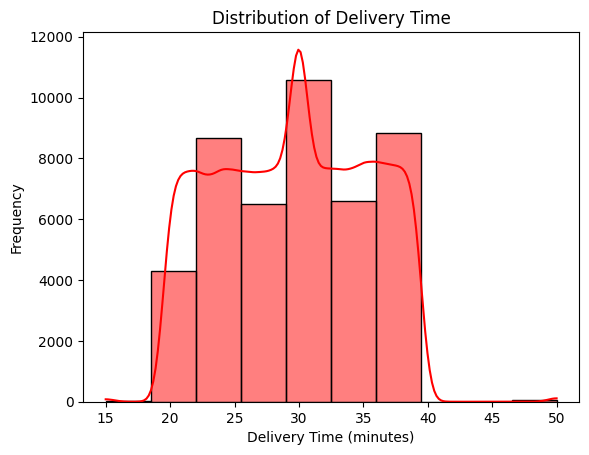

In [162]:
sns.histplot(df['Delivery_person_Age'],bins=10, kde=True, color='red')
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Frequency")
plt.show()

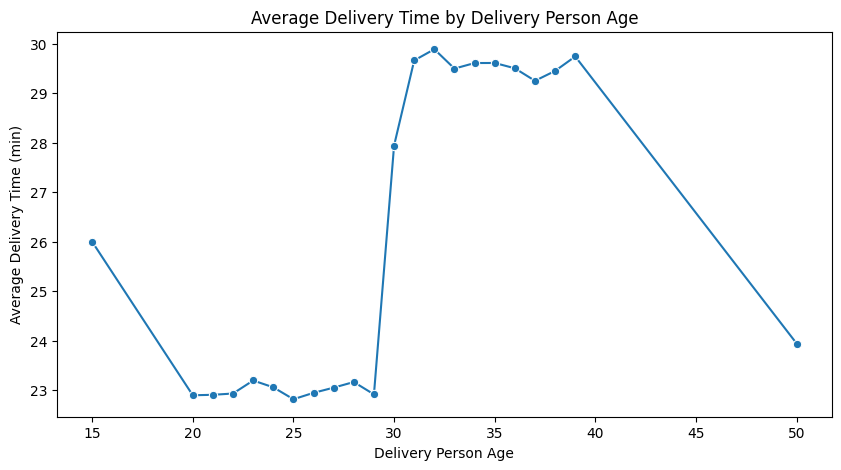

In [163]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Delivery_person_Age', y='Time_taken(min)', data=df, estimator='mean', errorbar=None, marker='o')
plt.title('Average Delivery Time by Delivery Person Age')
plt.xlabel('Delivery Person Age')
plt.ylabel('Average Delivery Time (min)')
plt.show()

In [164]:
df['Delivery_person_Ratings'].describe()

,Delivery_person_Ratings
count,45593.000000
mean,4.635389
std,0.324828
min,1.000000
25%,4.600000
50%,4.700000
75%,4.800000
max,5.000000


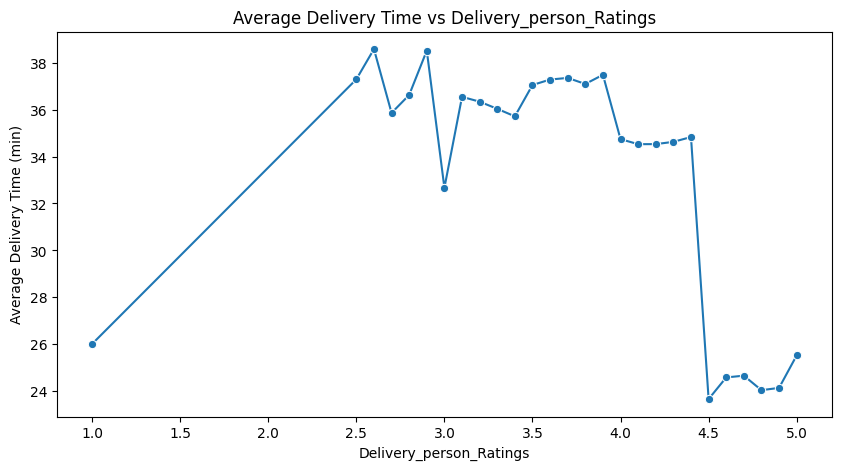

In [165]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Delivery_person_Ratings', y='Time_taken(min)', data=df, estimator='mean', errorbar=None, marker='o')
plt.title('Average Delivery Time vs Delivery_person_Ratings')
plt.xlabel('Delivery_person_Ratings')
plt.ylabel('Average Delivery Time (min)')
plt.show()

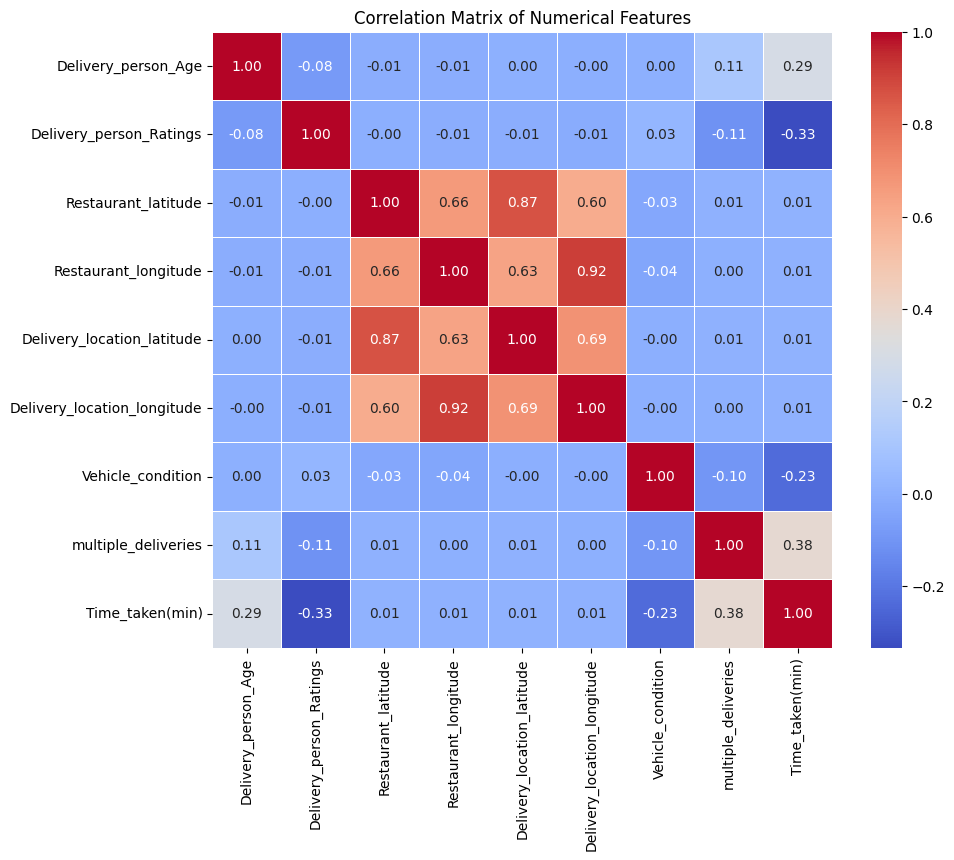

In [166]:
# Select numeric columns and compute correlation
numeric_cols = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_cols.corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [167]:
df['Order_Date']

,Order_Date
0,19-03-2022
1,25-03-2022
2,19-03-2022
3,05-04-2022
4,26-03-2022
...,...
45588,24-03-2022
45589,16-02-2022
45590,11-03-2022
45591,07-03-2022


In [168]:
df['Time_Orderd']

,Time_Orderd
0,11:30:00
1,19:45:00
2,08:30:00
3,18:00:00
4,13:30:00
...,...
45588,11:35:00
45589,19:55:00
45590,23:50:00
45591,13:35:00


In [169]:
hour=pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S',errors='coerce').dt.hour

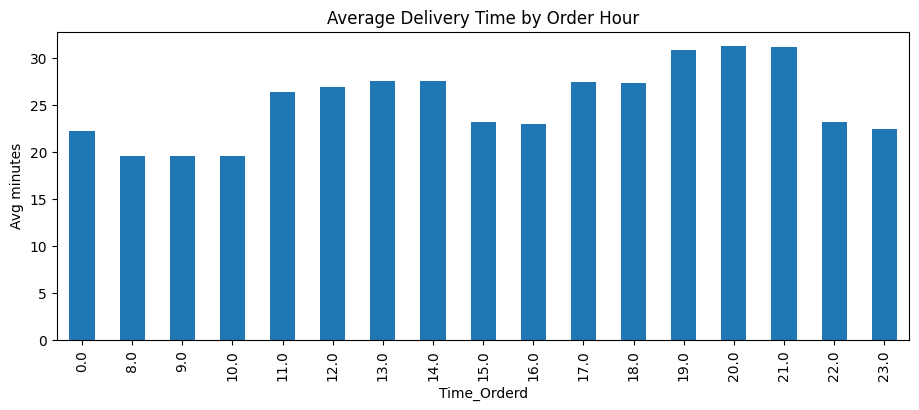

In [170]:
df.groupby(hour)['Time_taken(min)'].mean().plot(kind='bar',figsize=(11,4))
plt.title('Average Delivery Time by Order Hour')
plt.ylabel('Avg minutes')
plt.show()


In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [172]:
def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of

    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """

    r = 3956 if miles else 6371
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * r


In [173]:
# Calculate the distance between the restaurant and delivery location using the Haversine function
df['distance_km'] = calculate_series_distance(
    df['Restaurant_latitude'],
    df['Restaurant_longitude'],
    df['Delivery_location_latitude'],
    df['Delivery_location_longitude']
)

# Quick statistical summary of the new distance column
display(df['distance_km'].describe())

,distance_km
count,45593.000000
mean,99.303911
std,1099.731281
min,1.465067
25%,4.663493
50%,9.264281
75%,13.763977
max,19692.674606


In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [175]:
df['distance_km'].describe()

,distance_km
count,45593.000000
mean,99.303911
std,1099.731281
min,1.465067
25%,4.663493
50%,9.264281
75%,13.763977
max,19692.674606


In [176]:
df[df['distance_km']>100]['distance_km'].describe()

,distance_km
count,431.000000
mean,9484.671093
std,6252.618252
min,2216.065794
25%,4434.856783
50%,5897.015762
75%,17132.390571
max,19692.674606


In [177]:
df[df['distance_km']<100]['distance_km'].describe()

,distance_km
count,45162.000000
mean,9.735396
std,5.608508
min,1.465067
25%,4.663412
50%,9.220209
75%,13.681490
max,20.969489


In [178]:
df=df[df['distance_km']<100].reset_index(drop=True)


In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  object 
 1   Delivery_person_ID           45162 non-null  object 
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  object 
 9   Time_Orderd                  43706 non-null  object 
 10  Time_Order_picked            45162 non-null  object 
 11  Weatherconditions            45162 non-null  object 
 12  Road_traffic_density         45162 non-null  object 
 13  Vehicle_conditio

Encoding


In [180]:
# Traffic density has a real order (Low < Medium < High < Jam) -> ordinal encode instead of one-hot,
# so the model can learn a single, sensible increasing relationship
traffic_mapping={
    'Low':0,
    'Medium': 1,
    'High' : 2,
    'Jam' : 3
}

df['Road_traffic_density']=df['Road_traffic_density'].map(traffic_mapping)

In [181]:
df.info('Road_traffic_density')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  object 
 1   Delivery_person_ID           45162 non-null  object 
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  object 
 9   Time_Orderd                  43706 non-null  object 
 10  Time_Order_picked            45162 non-null  object 
 11  Weatherconditions            45162 non-null  object 
 12  Road_traffic_density         45162 non-null  int64  
 13  Vehicle_conditio

In [182]:
import pandas as pd
import numpy as np

def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of
    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """
    r = 3956 if miles else 6371
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * r

# 1. Reload the dataset fresh
df = pd.read_csv('/content/Food delivery.csv')

# 2. Clean text column string values and spaces
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
    df[col] = df[col].replace('NaN', np.nan)

# 3. Clean specific columns containing prefixes
if 'Weatherconditions' in df.columns:
    df['Weatherconditions'] = df['Weatherconditions'].apply(lambda temp: temp.split(' ')[1] if pd.notnull(temp) and ' ' in str(temp) else temp)
if 'Time_taken(min)' in df.columns:
    df['Time_taken(min)'] = df['Time_taken(min)'].apply(lambda temp: int(temp.split(' ')[1]) if pd.notnull(temp) and ' ' in str(temp) else temp)

# 4. Cast numeric types
for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5. Handle out-of-bounds ratings & fill missing values
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].clip(upper=5)
for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
    df[col] = df[col].fillna(df[col].median())
for col in ['Weatherconditions', 'Road_traffic_density', 'Festival', 'City']:
    df[col] = df[col].fillna(df[col].mode()[0])

# 6. Apply distance calculations and remove outliers
df['distance_km'] = calculate_series_distance(
    df['Restaurant_latitude'],
    df['Restaurant_longitude'],
    df['Delivery_location_latitude'],
    df['Delivery_location_longitude']
)
df = df[df['distance_km'] < 100].reset_index(drop=True)

# 7. Map ordinal traffic density
traffic_mapping = {'Low': 0, 'Medium': 1, 'High': 2, 'Jam': 3}
df['Road_traffic_density'] = df['Road_traffic_density'].map(traffic_mapping)

# 8. Apply get_dummies
df = pd.get_dummies(df, columns=['Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'Weatherconditions'], drop_first=True, dtype=int)

print("Dataset successfully reloaded, cleaned, and encoded!")
display(df.head())

Dataset successfully reloaded, cleaned, and encoded!


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_NaN,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,0,0,0,1,0,0,0,0,1,0
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,1,0,0,0,0,0,0,1,0,0
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,0,0,0,1,0,0,1,0,0,0
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,...,0,0,0,0,0,0,0,0,1,0
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,...,1,0,0,0,0,0,0,0,0,0


In [183]:
from sklearn.model_selection import train_test_split

# Define the target variable (y)
y = df['Time_taken(min)']

# Define the feature set (X) by dropping non-predictive or target columns
X = df.drop(columns=['ID', 'Delivery_person_ID', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Time_taken(min)'])

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Data successfully split! Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Data successfully split! Training set shape: (36129, 25), Test set shape: (9033, 25)


In [184]:
X_train.shape, X_test.shape

((36129, 25), (9033, 25))

Feature Sacling

Standardize all features to mean 0 / std 1. Needed for Linear Regression (distance-based math); tree-based models don't need it, but scaling doesn't hurt them either, so we apply it once for all models.


In [185]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()


In [186]:
# Fit the scaler on TRAIN ONLY, then apply it to both - never fit on test data
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [187]:
X_train_scaled


array([[-1.33517305,  0.51156709, -0.59788695, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 1.12628719,  0.19877778, -2.35833795, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [-0.80771728, -0.42680083, -0.58803653, ...,  2.23997508,
        -0.43645196, -0.44093773],
       ...,
       [ 1.65374296, -0.11401152,  1.2916728 , ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 0.77465001,  0.51156709, -0.59982712, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [ 0.77465001, -1.36516875,  1.2999199 , ..., -0.44643354,
        -0.43645196, -0.44093773]])

In [188]:
# Put back into DataFrames with the original column names/index for readability
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns,index=X_train.index)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)


In [189]:
import joblib
# Save the fitted scaler
joblib.dump(scaler, "standard_scaler.pkl")


['standard_scaler.pkl']

Model 1 — Linear Regression (baseline)

Simplest possible model: fits one straight-line relationship across all features. Fast and interpretable


In [190]:
from sklearn.linear_model import LinearRegression


In [191]:
lr=LinearRegression()


In [192]:
lr.fit(X_train_scaled,y_train)


LinearRegression()

In [193]:
# One coefficient per feature (in the scaled space) – larger magnitude = bigger influence
lr.coef_


array([ 2.25075587e+00, -2.16837308e+00,  9.70288456e+05, -2.80920105e+06,
       -9.70469657e+05,  2.80921680e+06,  2.88545642e+00, -1.81096183e+00,
        1.72537520e+00,  4.87458590e+00, -6.63552577e-02, -2.23528395e-02,
       -1.35449527e-02,  4.62508154e-01,  6.25805835e-01,  3.49914164e-01,
        1.33007638e+00,  5.83313232e-01, -8.07553167e-01,  2.06146464e-02,
        3.43074934e-01, -1.00747427e+00, -1.00701235e+00, -2.30974440e+00,
       -9.68076131e-01])

In [194]:
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Road_traffic_density',
       'Vehicle_condition', 'multiple_deliveries', 'distance_km',
       'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack',
       'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle',
       'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban',
       'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_NaN',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='object')

In [195]:
from sklearn.metrics import r2_score, mean_squared_error

In [196]:
y_pred_test = lr.predict(X_test_scaled)

In [197]:
rmse_test=np.sqrt(mean_squared_error(y_test,y_pred_test))

In [198]:
rmse_train=np.sqrt(mean_squared_error(y_train,lr.predict(X_train_scaled)))

In [199]:
r2_test=r2_score(y_test,y_pred_test)

In [200]:
r2_train=r2_score(y_train,lr.predict(X_train_scaled))

In [201]:
print(rmse_train,r2_train)

6.051888476187973 0.582189724824766


In [202]:
print(rmse_test,r2_test)

6.217143009246254 0.5686729898681041


Model 2 — Decision Tree

Splits the data with a series of yes/no questions on features ("is traffic Jam?", "is distance > 5km?") to separate slow orders from fast ones. Powerful, but an unconstrained tree will memorize the training data.



In [203]:
from sklearn.tree import DecisionTreeRegressor

In [204]:
dt=DecisionTreeRegressor(random_state=42)

In [205]:
dt.fit(X_train_scaled,y_train)

DecisionTreeRegressor(random_state=42)

In [206]:
y_pred_test = dt.predict(X_test_scaled)

In [207]:
# Test performance
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,dt.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,dt.predict(X_test_scaled))
print("dt rmse",rmse)
print("dt r2",r2)


dt rmse 5.396531353344051
dt r2 0.6750217096678006


In [208]:
# Now check TRAIN performance for comparison - this is how we catch overfitting
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_train,dt.predict(X_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train,dt.predict(X_train_scaled))
print("dt train rmse",rmse)
print("dt train r2",r2)


dt train rmse 0.0400669262136867
dt train r2 0.9999816865850325


Model 3 — Random Forest

Hundreds of decision trees, each trained on a random subset of rows and features, with predictions averaged. Individual trees' errors tend to cancel out, which is why forests overfit far less than a single deep tree.


In [209]:
from sklearn.ensemble import RandomForestRegressor


In [210]:
rf=RandomForestRegressor(n_estimators=100,random_state=42)


In [211]:
rf.fit(X_train_scaled,y_train)


RandomForestRegressor(random_state=42)

In [213]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
# Predict using the Random Forest model 'rf'
y_pred_rf = rf.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("rf rmse", rmse)
print("rf r2", r2)

rf rmse 4.045779441496504
rf r2 0.8173459329737446


In [214]:
# Train
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
# Predict using the Random Forest model 'rf'
y_pred_rf = rf.predict(X_train_scaled)

mse = mean_squared_error(y_train, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_pred_rf)

print("rf rmse", rmse)
print("rf r2", r2)

rf rmse 1.5135886246975634
rf r2 0.9738655723072478


Tuning: randomized search over tree count/depth/features — cheaper than a full grid search over this many hyperparameters.


In [221]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_param_dist = {
    'n_estimators': [20, 50, 80],
    'max_depth': [8, 12, 15, None],
    'min_samples_leaf': [2, 4, 8],
    'min_samples_split': [5, 10],
    'max_features': ['sqrt', 0.5]
}

# Sample 5 random combinations instead of 25 to avoid long execution times
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_param_dist,
    n_iter=5,
    cv=2,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train_scaled, y_train)
print("best params", rf_search.best_params_)
rf_best = rf_search.best_estimator_

best params {'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 15}


In [222]:
r2_rf_tuned=r2_score(y_test,rf_best.predict(X_test_scaled))
rmse_rf_tuned=np.sqrt(mean_squared_error(y_test,rf_best.predict(X_test_scaled)))
print("tuned rf rmse",rmse_rf_tuned)
print("tuned rf r2",r2_rf_tuned)


tuned rf rmse 3.9663471117728513
tuned rf r2 0.8244477591976629


In [223]:
# which feature the forest leans on
rf.feature_importances_

array([0.09589404, 0.20291354, 0.01604774, 0.0171957 , 0.0186554 ,
       0.01950511, 0.12591321, 0.06915099, 0.11951504, 0.1124605 ,
       0.00376933, 0.00402571, 0.00390301, 0.00153476, 0.0020373 ,
       0.00221036, 0.01303141, 0.00208408, 0.00547099, 0.03303062,
       0.00227835, 0.02277201, 0.01778871, 0.06977056, 0.01904152])

In [224]:
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Road_traffic_density',
       'Vehicle_condition', 'multiple_deliveries', 'distance_km',
       'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack',
       'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle',
       'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban',
       'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_NaN',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='object')

Model 4 — XGBoost

Trees trained sequentially — each new tree specifically corrects the errors of all trees before it (gradient boosting). Usually the strongest single model for structured/tabular data like ours.


In [216]:
from xgboost import XGBRegressor


In [217]:
xgb=XGBRegressor(n_estimators=100,random_state=42)


In [218]:
xgb.fit(X_train_scaled,y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [220]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,xgb.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,xgb.predict(X_test_scaled))
print("xgb rmse",rmse)
print("xgb r2",r2)


xgb rmse 4.005294633521778
xgb r2 0.8209831714630127


In [226]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

xgb_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 0.5, 1],
    'reg_lambda': [1, 1.5, 2]
}

# Perform a randomized search over 10 iterations with 2-fold cross-validation for quick execution
xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    xgb_param_dist,
    n_iter=10,
    cv=2,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
xgb_search.fit(X_train_scaled, y_train)
print("best params", xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_

best params {'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 1, 'n_estimators': 150, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


In [227]:
r2_xgb_train=r2_score(y_train,xgb_best.predict(X_train_scaled))
rmse_xgb_train=np.sqrt(mean_squared_error(y_train,xgb_best.predict(X_train_scaled)))
print("xgb train rmse",rmse_xgb_train)
print("xgb train r2",r2_xgb_train)


xgb train rmse 3.9780970761981473
xgb train r2 0.8194705247879028


In [228]:
r2_xgb_test=r2_score(y_test,xgb_best.predict(X_test_scaled))
rmse_xgb_test=np.sqrt(mean_squared_error(y_test,xgb_best.predict(X_test_scaled)))
print("xgb rmse",rmse_xgb_test)
print("xgb r2",r2_xgb_test)


xgb rmse 4.171172007790988
xgb r2 0.8058483600616455


In [230]:
# Number of features p — needed for the adjusted R² formula below
X_test_scaled.shape[1]

25

In [229]:
# Test Adjusted R²
y_test_pred = xgb_best.predict(X_test_scaled)

n_test = len(y_test)
p_test = X_test_scaled.shape[1]

adj_r2_xgb_test = 1 - (1 - r2_xgb_test) * (n_test - 1) / (n_test - p_test - 1)

print("xgb test adjusted r2", adj_r2_xgb_test)

xgb test adjusted r2 0.8053094690881295


In [231]:
# Recall: X_train is the UNSCALED training features — we build the new feature here first
X_train

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Road_traffic_density,Vehicle_condition,multiple_deliveries,distance_km,...,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_NaN,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy
24844,22.0,4.8,12.949934,77.699386,12.999934,77.749386,1,2,1.0,7.762944,...,0,0,0,0,0,0,0,0,0,1
33010,36.0,4.7,0.000000,0.000000,0.110000,0.110000,3,2,2.0,17.297866,...,1,1,0,0,0,0,0,0,0,0
16599,25.0,4.5,13.022394,80.242439,13.132394,80.352439,3,2,0.0,17.075035,...,0,0,0,0,0,0,0,1,0,0
35248,38.0,4.8,21.157735,72.768778,21.177735,72.788778,2,1,0.0,3.040816,...,1,0,0,0,0,0,0,1,0,0
14293,26.0,5.0,0.000000,0.000000,0.020000,0.020000,0,0,1.0,3.145067,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,38.0,4.9,12.979096,77.640625,13.009096,77.670625,3,0,1.0,4.657592,...,0,0,0,0,0,0,0,0,0,1
44732,30.0,4.7,12.972161,77.596014,13.102161,77.726014,0,0,0.0,20.181187,...,0,0,0,0,0,0,0,0,0,1
38158,39.0,4.6,26.849596,75.800512,26.889596,75.840512,2,2,1.0,5.960265,...,0,0,0,0,0,0,0,0,0,1
860,34.0,4.8,12.935662,77.614130,12.955662,77.634130,0,1,1.0,3.105356,...,1,0,0,0,1,0,0,0,0,0


In [232]:
# Bucket the order hour into meal periods (lunch / dinner rushes vs the rest)
def order_period(hour):
  if 12<=hour<=14 :
    return "Lunch"
  elif 19<=hour<=21 :
    return "Dinner"
  else :
    return "Normal"

In [233]:
# 1. Copy unscaled data
X_train_exp = X_train.copy()
X_test_exp = X_test.copy()

In [235]:
# 2. Create the new feature BEFORE scaling by extracting the hour from the original 'Time_Orderd' column in df
train_hours = pd.to_datetime(df.loc[X_train_exp.index, 'Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour
test_hours = pd.to_datetime(df.loc[X_test_exp.index, 'Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour

X_train_exp['order_period'] = train_hours.apply(order_period)
X_test_exp['order_period'] = test_hours.apply(order_period)

In [236]:
# Confirm the new order_period column landed correctly
X_train_exp

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Road_traffic_density,Vehicle_condition,multiple_deliveries,distance_km,...,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_NaN,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy,order_period
24844,22.0,4.8,12.949934,77.699386,12.999934,77.749386,1,2,1.0,7.762944,...,0,0,0,0,0,0,0,0,1,Normal
33010,36.0,4.7,0.000000,0.000000,0.110000,0.110000,3,2,2.0,17.297866,...,1,0,0,0,0,0,0,0,0,Dinner
16599,25.0,4.5,13.022394,80.242439,13.132394,80.352439,3,2,0.0,17.075035,...,0,0,0,0,0,0,1,0,0,Dinner
35248,38.0,4.8,21.157735,72.768778,21.177735,72.788778,2,1,0.0,3.040816,...,0,0,0,0,0,0,1,0,0,Normal
14293,26.0,5.0,0.000000,0.000000,0.020000,0.020000,0,0,1.0,3.145067,...,0,0,0,1,0,0,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,38.0,4.9,12.979096,77.640625,13.009096,77.670625,3,0,1.0,4.657592,...,0,0,0,0,0,0,0,0,1,Dinner
44732,30.0,4.7,12.972161,77.596014,13.102161,77.726014,0,0,0.0,20.181187,...,0,0,0,0,0,0,0,0,1,Normal
38158,39.0,4.6,26.849596,75.800512,26.889596,75.840512,2,2,1.0,5.960265,...,0,0,0,0,0,0,0,0,1,Lunch
860,34.0,4.8,12.935662,77.614130,12.955662,77.634130,0,1,1.0,3.105356,...,0,0,0,1,0,0,0,0,0,Normal


In [237]:
# 3. One-hot encode
X_train_exp = pd.get_dummies(
    X_train_exp, columns=['order_period'], drop_first=True, dtype=int
)

X_test_exp = pd.get_dummies(
    X_test_exp, columns=['order_period'], drop_first=True, dtype=int
)


In [238]:
# 4. Create a NEW scaler and fit ONLY on expanded training data
scaler_exp = StandardScaler()

X_train_exp_scaled = scaler_exp.fit_transform(X_train_exp)
X_test_exp_scaled = scaler_exp.transform(X_test_exp)

In [239]:
# Retrain our strongest model (same tuned hyperparameters) WITH the new feature, for a fair comparison
xgb_with_period = XGBRegressor(**xgb_search.best_params_, random_state=42)
xgb_with_period.fit(X_train_exp_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=150,
             n_jobs=None, num_parallel_tree=None, ...)

In [240]:
n_test = X_test_exp.shape[0]
p_test = X_test_exp.shape[1]
r2_with_period_test = r2_score(y_test, xgb_with_period.predict(X_test_exp_scaled))
adj_r2_test = 1 - (1 - r2_with_period_test) * (n_test - 1) / (n_test - p_test - 1)
print("Test Adjusted R²:", adj_r2_test)

Test Adjusted R²: 0.8038151668482922


In [241]:
joblib.dump(xgb_best, "xgb_best.pkl")

['xgb_best.pkl']

In [242]:
model = joblib.load("/content/xgb_best.pkl")
scaler = joblib.load("/content/standard_scaler.pkl")

In [243]:
# Grab 3 raw (unscaled) test rows to mimic new incoming orders
sample=X_test[0:3]

In [244]:
# Apply the SAME scaler the model was trained with
sample_scaled=scaler.transform(sample)

In [245]:
# Predict delivery time (minutes) for the 3 samples
predictions=model.predict(sample_scaled)

In [246]:
# Model's predicted minutes
predictions

array([38.772312, 20.016632, 36.8868  ], dtype=float32)

In [247]:
# Actual minutes — compare against the predictions above
y_test[0:3].values

array([46, 19, 40])

In [248]:
sample=X_test[0:8]

In [249]:
sample_scaled=scaler.transform(sample)

In [250]:
predictions=model.predict(sample_scaled)

In [251]:
predictions

array([38.772312, 20.016632, 36.8868  , 33.61882 , 31.033108, 35.574738,
       32.75075 , 14.803894], dtype=float32)

In [252]:
y_test[0:8].values

array([46, 19, 40, 36, 33, 38, 32, 19])